In [2]:
import pandas as pd

Load the dataset

In [3]:
df = pd.read_csv("/Users/ishik/Desktop/practical-stats-for-data-scientist/chapter-01-eda/data/hour.csv",index_col="instant")

In [4]:
df.shape

(17379, 16)

In [5]:
df.head()

,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
instant,,,,,,,,,,,,,,,,
1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 1 to 17379
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  str    
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  casual      17379 non-null  int64  
 14  registered  17379 non-null  int64  
 15  cnt         17379 non-null  int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 2.1 MB


Check for null values in all the columns

In [7]:
df.isnull().sum()

dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Check for duplicated rows

In [8]:
df.duplicated().sum()

np.int64(0)

Check if cnt column is sum of casual and registered column for all the rows

In [9]:
(df['cnt'] == df['casual'] + df['registered']).all()

np.True_

Fix the datatypes for the required columns

In [10]:
df['dteday'] = pd.to_datetime(df['dteday'])

In [11]:
cols = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit']
df[cols] = df[cols].astype('category')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 1 to 17379
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[us]
 1   season      17379 non-null  category      
 2   yr          17379 non-null  category      
 3   mnth        17379 non-null  category      
 4   hr          17379 non-null  category      
 5   holiday     17379 non-null  category      
 6   weekday     17379 non-null  category      
 7   workingday  17379 non-null  category      
 8   weathersit  17379 non-null  category      
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  casual      17379 non-null  int64         
 14  registered  17379 non-null  int64         
 15  cnt         17379 non-null  int64         
dtypes: category(8), datetime64[us](1)

In [13]:
df.select_dtypes(include='number').describe()

,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Calculate the coefficient of variation for casual and registered columns

In [14]:
cv = (df[['casual','registered','cnt']].std()/df[['casual','registered','cnt']].mean()) 
cv

casual        1.382014
registered    0.984202
cnt           0.957377
dtype: float64

Calculate the 90th and 95th percentile for the cnt column

In [15]:
df['cnt'].quantile(0.90)

np.float64(451.2000000000007)

In [16]:
df['cnt'].quantile(0.95)

np.float64(563.0999999999985)

Calculate the skewness of the casual, registered and cnt columns

In [17]:
df[['casual','registered','cnt']].skew()

casual        2.499237
registered    1.557904
cnt           1.277412
dtype: float64

In [18]:
import matplotlib.pyplot as plt

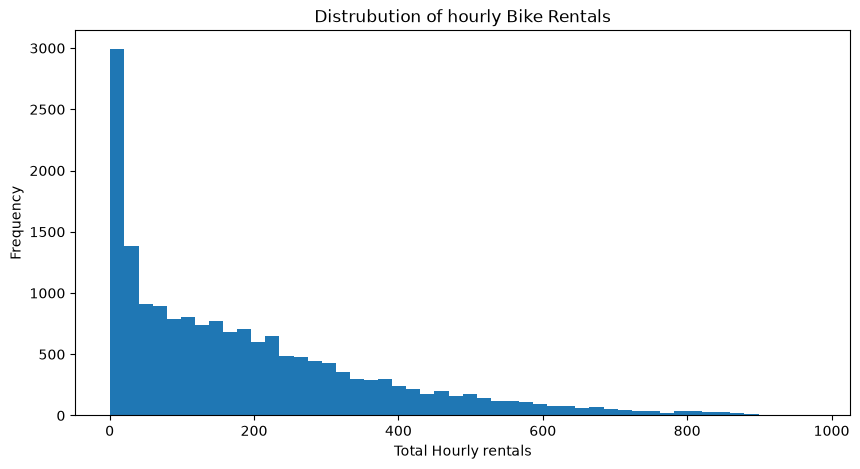

In [19]:
plt.figure(figsize=(10,5))
plt.hist(df['cnt'],bins=50)
plt.xlabel("Total Hourly rentals")
plt.ylabel("Frequency")
plt.title("Distrubution of hourly Bike Rentals")
plt.show()

/var/folders/k1/8_nwyhzd63x2h3q29fcsft7r0000gn/T/ipykernel_3686/3926681327.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['cnt'],vert=False)


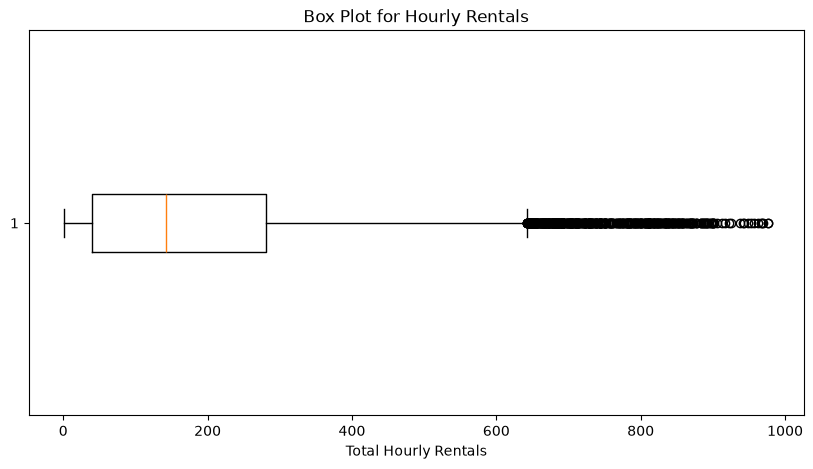

In [20]:
plt.figure(figsize=(10,5))
plt.boxplot(df['cnt'],vert=False)
plt.xlabel("Total Hourly Rentals")
plt.title("Box Plot for Hourly Rentals")
plt.show()

Investigate the outliers

In [21]:
q1 = df['cnt'].quantile(0.25)
q3 = df['cnt'].quantile(0.75)
IQR = q3 - q1

Lower_bound = q1 - 1.5 * IQR
Upper_bound = q3 + 1.5 * IQR



Investigate the outliers the upper and lower end - if they are affected by hour, seasons and working days or holidays

In [22]:
lower_outliers = df[df['cnt'] < Lower_bound]
upper_outliers = df[df['cnt'] > Upper_bound]

In [23]:
col = ['season','hr','weekday','workingday']
for x in col:
    print(x,lower_outliers[x].unique())

season [], Categories (4, int64): [1, 2, 3, 4]
hr [], Categories (24, int64): [0, 1, 2, 3, ..., 20, 21, 22, 23]
weekday [], Categories (7, int64): [0, 1, 2, 3, 4, 5, 6]
workingday [], Categories (2, int64): [0, 1]


In [24]:
col = ['season','hr','weekday','workingday']
for x in col:
    print(x,upper_outliers[x].unique())

season [3, 1, 2, 4]
Categories (4, int64): [1, 2, 3, 4]
hr [14, 17, 18, 8, 12, 13, 15, 16, 19, 11]
Categories (24, int64): [0, 1, 2, 3, ..., 20, 21, 22, 23]
weekday [2, 1, 3, 4, 6, 5, 0]
Categories (7, int64): [0, 1, 2, 3, 4, 5, 6]
workingday [1, 0]
Categories (2, int64): [0, 1]


In [25]:
hourly_demand = df.groupby('hr')['cnt'].mean()
hourly_demand


hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

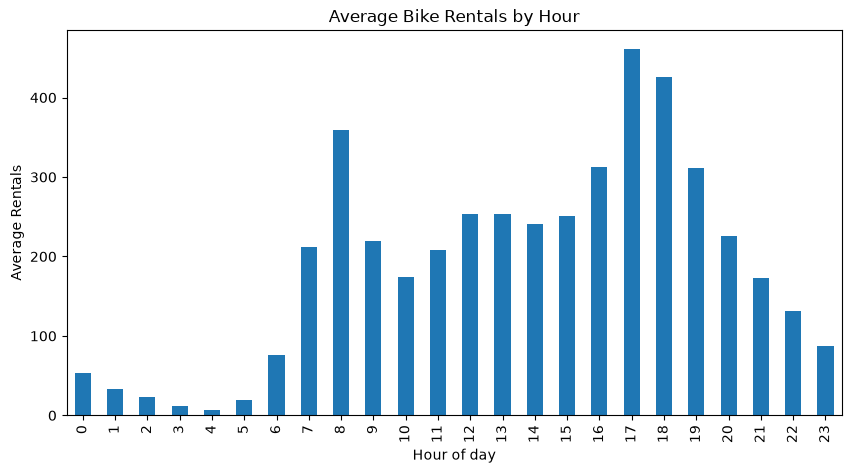

In [26]:
plt.figure(figsize=(10,5))
hourly_demand.plot(kind="bar",title="Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average Rentals")
plt.show()

Registered vs casual users average bike rentals by Hour

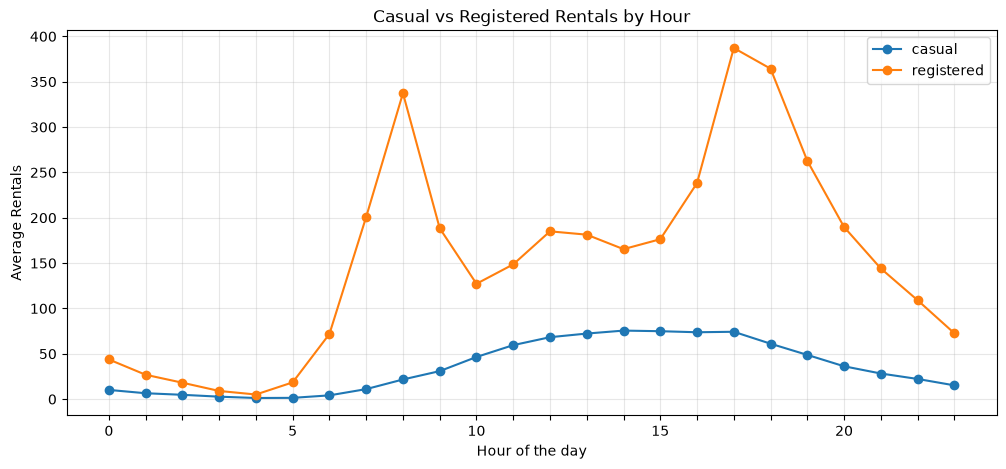

In [27]:
user_hourly = df.groupby('hr')[['casual','registered']].mean()
user_hourly.plot(figsize=(12,5),marker="o")

plt.xlabel("Hour of the day")
plt.ylabel("Average Rentals")
plt.title("Casual vs Registered Rentals by Hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

- Morning peak: is less prominent for casual users and strong for registred users 
- Afternoon: higher relative activity for casual users and lower for registered users
- 5 PM: for both of the user groups the demand is highest 
- After PM: the demand decreases for both groups
- Overall pattern: gradual increase and decrease for casual users and registred useres two prominent peaks

Potential business implications:
- Registered-user demand may be associated with commuting patterns.
- Casual-user demand may be more associated with daytime recreational activity.
- Bike availability planning could benefit from considering customer segments separately.
- These are exploratory observations and hypotheses, not causal conclusions.

Registered vs Casual users rental difference

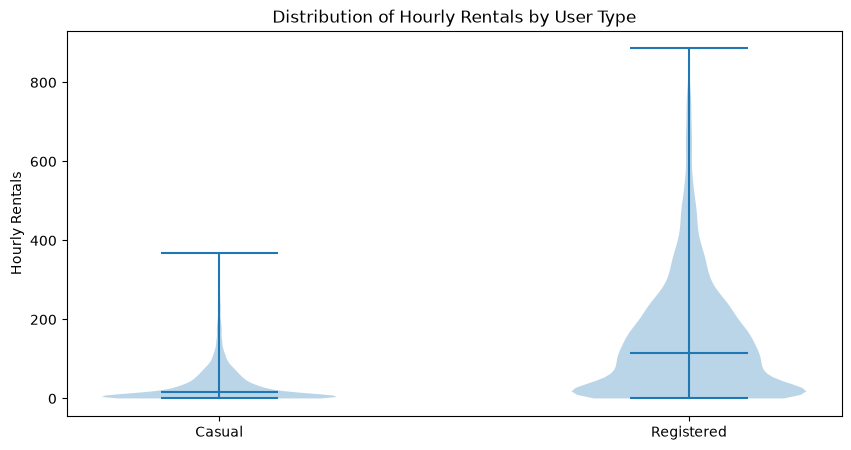

In [33]:
plt.figure(figsize=(10,5))
plt.violinplot([df['casual'],df['registered']],showmedians=True)

plt.xticks(ticks=[1,2],labels=['Casual','Registered'])
plt.ylabel('Hourly Rentals')
plt.title('Distribution of Hourly Rentals by User Type')
plt.show()

### Finding: Distribution of casual and registered rentals

- The violin plot shows that registered users have a substantially higher median hourly rental count and greater absolute spread than casual users.

- Casual rentals exhibit a wider density region at certain lower rental counts, indicating a concentration of observations around those values.

- Both distributions have longer upper tails, consistent with the positive skewness observed in the descriptive statistics.

- This reinforces the distinction between absolute variability (higher for registered users) and relative variability (higher for casual users).

Investigate the temperature association with bike rental demand

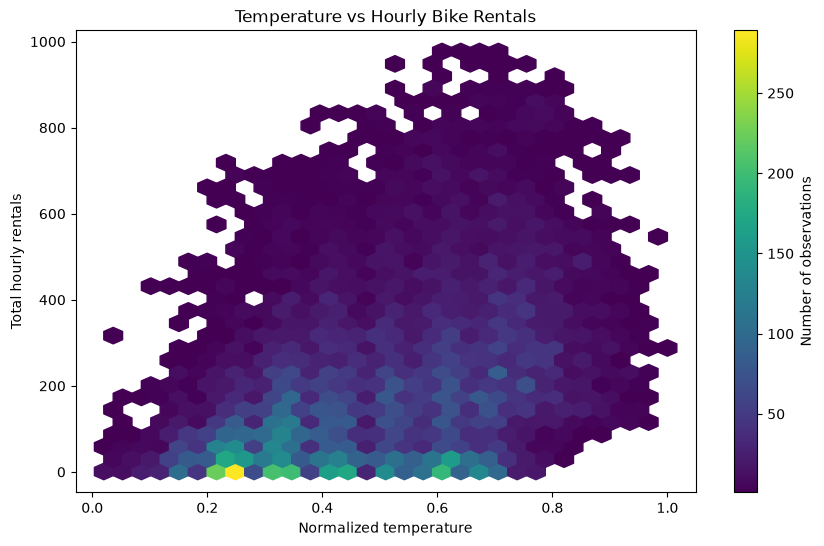

In [35]:
plt.figure(figsize=(10, 6))

plt.hexbin(
    df["temp"],
    df["cnt"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(label="Number of observations")
plt.xlabel("Normalized temperature")
plt.ylabel("Total hourly rentals")
plt.title("Temperature vs Hourly Bike Rentals")

plt.show()

- The hexagonal binning plot suggests a positive association between normalized temperature and total hourly bike rentals.
- Higher rental counts appear more frequently at higher temperatures. 
- However, there is considerable spread in rental counts across temperature levels, suggesting that temperature alone may not explain variations in demand.

In [39]:
from scipy.stats import pearsonr, spearmanr

pearson_corr, pearson_p = pearsonr(df["temp"], df["cnt"])
spearman_corr, spearman_p = spearmanr(df["temp"], df["cnt"])

print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)
print(f"Pearson p-value: {pearson_p:.10e}")
print(f"Spearman p-value: {spearman_p:.10e}")

Pearson: 0.4047722757786586
Spearman: 0.4233295244770643
Pearson p-value: 0.0000000000e+00
Spearman p-value: 0.0000000000e+00


- Temperature has a moderate positive association with total hourly bike rentals. 
- Pearson and Spearman correlation coefficients are similar (0.405 and 0.423, respectively), indicating a broadly consistent positive relationship. Both tests produce extremely small p-values, suggesting strong statistical evidence against zero correlation.
- However, correlation does not establish causation, and other variables may influence rental demand.

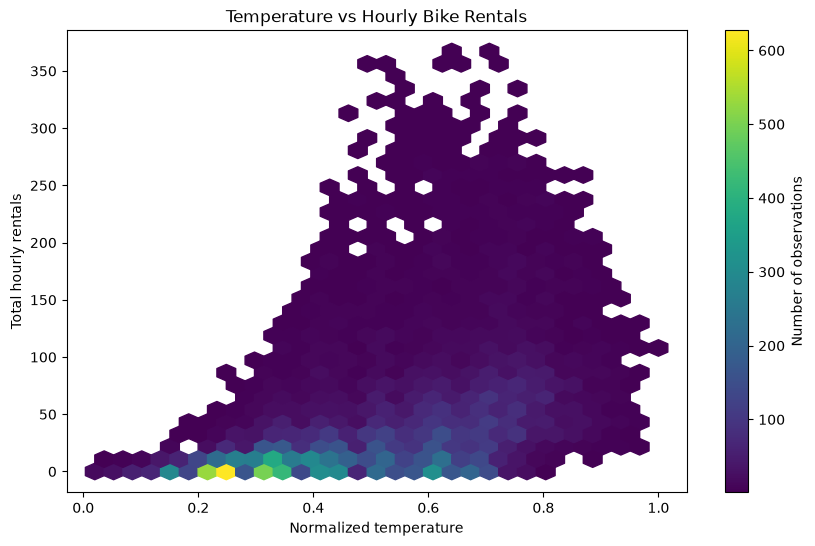

In [41]:
plt.figure(figsize=(10, 6))

plt.hexbin(
    df["temp"],
    df["casual"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(label="Number of observations")
plt.xlabel("Normalized temperature")
plt.ylabel("Total hourly rentals")
plt.title("Temperature vs Hourly Bike Rentals")

plt.show()

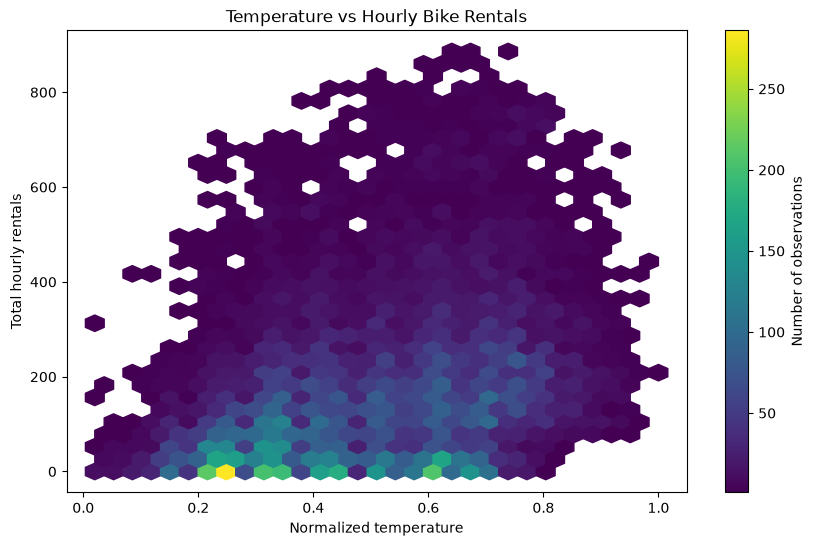

In [42]:
plt.figure(figsize=(10, 6))

plt.hexbin(
    df["temp"],
    df["registered"],
    gridsize=30,
    cmap="viridis",
    mincnt=1
)

plt.colorbar(label="Number of observations")
plt.xlabel("Normalized temperature")
plt.ylabel("Total hourly rentals")
plt.title("Temperature vs Hourly Bike Rentals")

plt.show()

In [43]:
pearson_corr, pearson_p = pearsonr(df["temp"], df["casual"])
spearman_corr, spearman_p = spearmanr(df["temp"], df["casual"])

print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)
print(f"Pearson p-value: {pearson_p:.10e}")
print(f"Spearman p-value: {spearman_p:.10e}")

Pearson: 0.459615645544846
Spearman: 0.5709886387968858
Pearson p-value: 0.0000000000e+00
Spearman p-value: 0.0000000000e+00


In [44]:
pearson_corr, pearson_p = pearsonr(df["temp"], df["registered"])
spearman_corr, spearman_p = spearmanr(df["temp"], df["registered"])

print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)
print(f"Pearson p-value: {pearson_p:.10e}")
print(f"Spearman p-value: {spearman_p:.10e}")

Pearson: 0.3353608490429961
Spearman: 0.37319609952593547
Pearson p-value: 0.0000000000e+00
Spearman p-value: 0.0000000000e+00


- Both casual and registered rentals exhibit positive associations with temperature. 
- The association appears stronger for casual users based on visual inspection and correlation coefficients. 
- Registered rentals show a broader range of observed rental counts across temperature levels. 
- These findings suggest that temperature is associated with demand in both customer segments, although the strength of the association differs.

Does bike rental demand differ between working days and non-working days?

- workingday: 0 = non-working day, 1 = working day.
- weathersit: 1 = Clear/Few clouds, 2 = Mist/Cloudy, 3 = Light snow/rain, 4 = Heavy rain/snow.

In [45]:
pd.crosstab(df['workingday'],df['weathersit'])

weathersit,1,2,3,4
workingday,,,,
0,3781,1353,379,1
1,7632,3191,1040,2


In [46]:
pd.crosstab(
    df["workingday"],
    df["weathersit"],
    normalize="index"
).round(3) * 100

weathersit,1,2,3,4
workingday,,,,
0,68.6,24.5,6.9,0.0
1,64.3,26.9,8.8,0.0


In [53]:
df.pivot_table(
    index="workingday",
    columns="weathersit",
    values="cnt",
    aggfunc="mean"
).round(2)

weathersit,1,2,3,4
workingday,,,,
0,197.62,156.68,108.30,23.0
1,208.46,183.01,112.78,100.0


- Average hourly rental demand is highest under clear weather conditions for both working and non-working days. Demand generally decreases as weather conditions worsen.
- Working days exhibit higher average rental demand than non-working days across the observed weather categories. 
- However, the heavy rain/snow category contains only three observations, making its average unreliable. 
- These patterns indicate an association between weather conditions, working-day status and rental demand.

In [55]:
weather_demand = df.pivot_table(
    index="weathersit",
    columns="workingday",
    values="cnt",
    aggfunc="mean"
)
weather_demand

workingday,0,1
weathersit,,
1,197.624702,208.458333
2,156.675536,183.005327
3,108.298153,112.775000
4,23.000000,100.000000


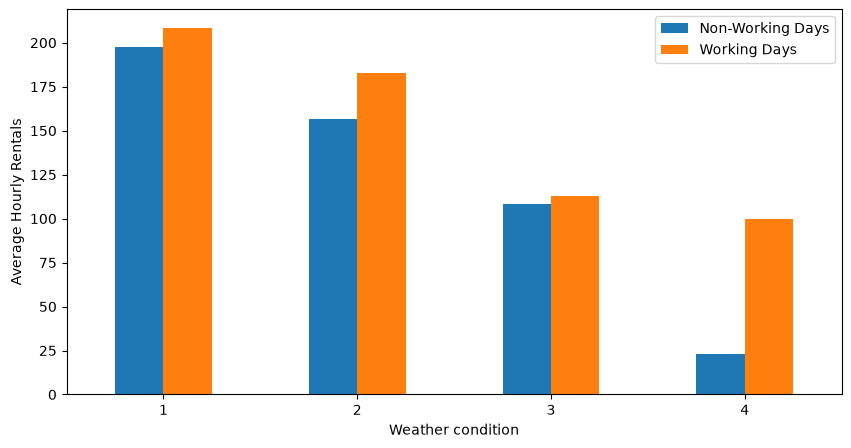

In [57]:
weather_demand.plot(kind='bar',figsize=(10,5))
plt.xlabel('Weather condition')
plt.ylabel('Average Hourly Rentals')
plt.xticks(rotation=0)
plt.legend(['Non-Working Days','Working Days'])
plt.show()